# 02 - Feature extraction & clustering
Compare TF-IDF vs sentence embeddings, then KMeans (elbow+silhouette) against
Agglomerative, DBSCAN and LDA. Report silhouette / Davies-Bouldin / coherence,
top terms + 5 samples per cluster, and a 2-D map. Finally emit an editable
cluster-name table and the 300-review `labeled_sample.csv` for manual fixing.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from src import DATA_PROCESSED, MODELS_DIR, set_seed
from src import features as ft, cluster as cl
set_seed(); sns.set_theme()
df = pd.read_csv(os.path.join(DATA_PROCESSED, 'reviews_clean.csv'))
# subsample to keep the 8GB laptop comfortable
df = df.sample(min(50000, len(df)), random_state=42).reset_index(drop=True)
print(df.shape)

(11159, 3)


## 1. Two feature representations

In [2]:
tfidf, vec = ft.build_tfidf(df['text'])
ft.save_vectorizer(vec)
emb = ft.build_embeddings(df['raw_text'])
print(ft.features_summary(tfidf, emb))

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|████████████████████████████| 175/175 [02:33<00:00,  1.14it/s]


{'tfidf_shape': (11159, 20000), 'tfidf_n_features': 20000, 'embedding_shape': (11159, 384), 'embedding_dim': 384}


## 2. KMeans: elbow + silhouette to choose k (4..12)

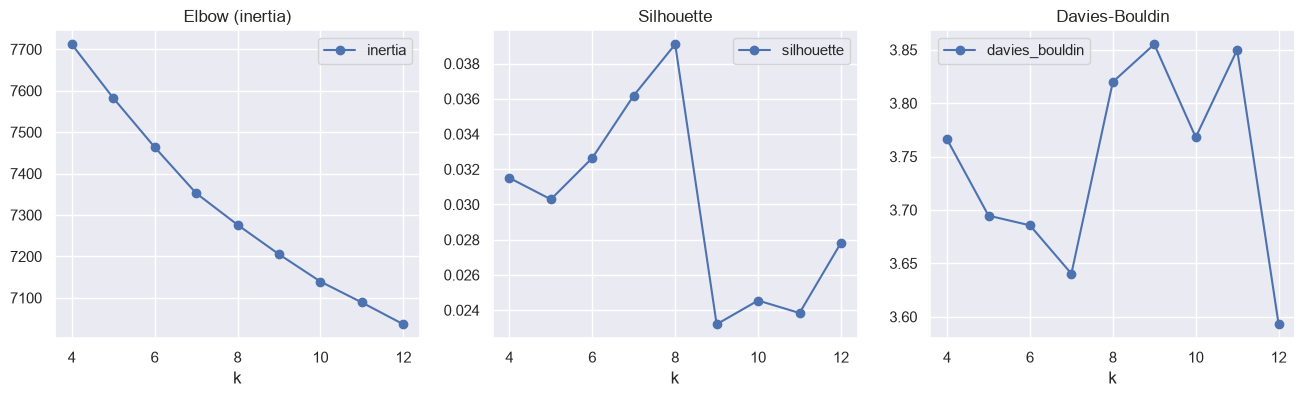

chosen k = 8


In [3]:
scan = cl.kmeans_elbow_silhouette(emb)
fig, axes = plt.subplots(1, 3, figsize=(16,4))
scan.plot(x='k', y='inertia', ax=axes[0], marker='o'); axes[0].set_title('Elbow (inertia)')
scan.plot(x='k', y='silhouette', ax=axes[1], marker='o'); axes[1].set_title('Silhouette')
scan.plot(x='k', y='davies_bouldin', ax=axes[2], marker='o'); axes[2].set_title('Davies-Bouldin')
plt.show()
K = int(scan.loc[scan['silhouette'].idxmax(), 'k'])
print('chosen k =', K)

## 3. Four methods side by side

In [4]:
_, km_labels = cl.fit_kmeans(emb, K)
_, agg_labels = cl.fit_agglomerative(emb, n_clusters=K)
_, dbs_labels = cl.fit_dbscan(emb, eps=0.75, min_samples=15)
compare = cl.compare_clusterings({
    'KMeans': (emb, km_labels),
    'Agglomerative': (emb, agg_labels),
    'DBSCAN': (emb, dbs_labels),
})
compare

,method,n_clusters,noise_pct,silhouette,davies_bouldin
2,DBSCAN,2,61.080742,0.159727,1.311075
0,KMeans,8,0.000000,0.039097,3.819930
1,Agglomerative,8,0.000000,0.022511,4.055041


In [5]:
# LDA needs raw tokens, not embeddings; score it with c_v coherence
lda_model, lda_dict, lda_corpus = cl.fit_lda(df['text'], n_topics=K)
coh = cl.lda_coherence(lda_model, lda_dict, df['text'])
print('LDA c_v coherence:', round(coh, 4))
cl.lda_topic_terms(lda_model, lda_dict)

LDA c_v coherence: 0.5646


,cluster,top_terms
0,0,calendar app feature would google not like add...
1,1,task time day list app not one widget option u...
2,2,app good great use like easy habit would task ...
3,3,app really love task help like time thing woul...
4,4,not task sync google no calendar account app d...
5,5,app notification not phone no get work cant us...
6,6,app version free premium ad feature not tree p...
7,7,app not work doesnt event dont good time need ...


## 4. Interpret the KMeans solution (chosen model)

In [6]:
df['cluster'] = km_labels
terms = cl.top_terms_per_cluster(tfidf, vec, km_labels, n_terms=12)
samples = cl.samples_per_cluster(df['raw_text'], km_labels, n=5)
display(terms)
for c in terms['cluster']:
    print('='*70, '\nCLUSTER', c)
    print('terms:', terms.loc[terms.cluster==c,'top_terms'].iloc[0])
    for t in samples[samples.cluster==c]['raw_text']:
        print('  -', t[:140])

,cluster,top_terms
0,0,app not work sync cant account widget update w...
1,1,good like not love far great work need bad nic...
2,2,reminder notification alarm app not work set t...
3,3,premium version free app ad not pay pro featur...
4,4,task list day time app add not would like opti...
5,5,calendar event google app google calendar not ...
6,6,easy use easy use good helpful useful simple g...
7,7,app good great good app love great app really ...


CLUSTER 0
terms: app not work sync cant account widget update working doesnt phone fix
  - We can easily close the recent apps and can use another applications in the deep focus mode.Please fix this issue.
  - The settings don't work well and it's really confusing when it doesn't function at all!!!! 😤
  - Difficult login forces work or school address. Lost Wunderlist lists as a result
  - The app is not opening please fix it It was running smooth before.
  - App is not starting.. just showing blank black screen
CLUSTER 1
terms: good like not love far great work need bad nice best dont
  - This makes me so much more productive!
  - نمیشه برای صفحه رنگی انتخاب کرد برای همین یه ستاره کم کردم وگرنه خیلی خوبه
  - Looked good until I used it
  - It's simple and fast...
  - I'm here for the Ninja Cerebral
CLUSTER 2
terms: reminder notification alarm app not work set time no doesnt dont sound
  - It just vibrate I never get an alert. It only list the task and vibrate when I open the app. It do

## 5. 2-D map (UMAP if installed, else PCA)

/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


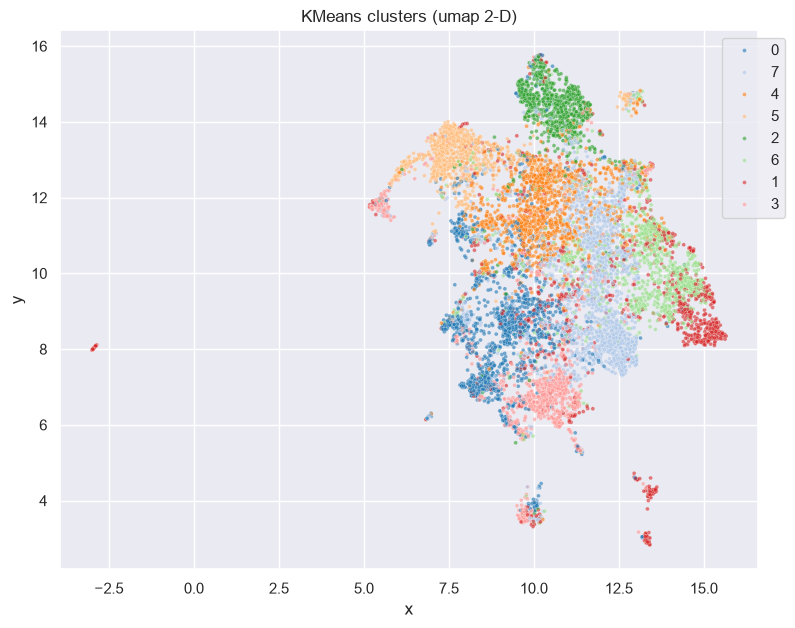

In [7]:
proj = cl.project_2d(emb, km_labels)
plt.figure(figsize=(9,7))
sns.scatterplot(data=proj, x='x', y='y', hue=proj['cluster'].astype(str),
                 palette='tab20', s=8, alpha=0.6)
plt.title(f"KMeans clusters ({proj.attrs['projection']} 2-D)")
plt.legend(bbox_to_anchor=(1.05,1)); plt.show()

## 6. Name clusters (edit config/cluster_names.json)

In [8]:
from src.predict import load_cluster_names, save_cluster_names
# Generate a starter mapping from top terms; then EDIT config/cluster_names.json
starter = {int(r.cluster): r.top_terms.split()[0] for r in terms.itertuples()}
print('starter names:', starter)
print('Edit config/cluster_names.json with human-readable names, then re-run.')

The history saving thread hit an unexpected error (OperationalError('database or disk is full')).History will not be written to the database.


/home/sudowoodo/Pro/review-organizer/.venv/lib/python3.14/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/sudowoodo/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


starter names: {0: 'app', 1: 'good', 2: 'reminder', 3: 'premium', 4: 'task', 5: 'calendar', 6: 'easy', 7: 'app'}
Edit config/cluster_names.json with human-readable names, then re-run.


## 7. Export 300-review sample for manual labelling

In [10]:
import json
names = load_cluster_names()
samp = df.sample(min(300, len(df)), random_state=42).copy()
samp['category_name'] = samp['cluster'].map(lambda c: names.get(int(c), f'cluster_{c}'))
out = samp[['raw_text','cluster','category_name']].rename(columns={'cluster':'cluster_id'})
# add a blank 'corrected_name' column for the human to fill in
out['corrected_name'] = ''
path = os.path.join(DATA_PROCESSED, 'labeled_sample.csv')
out.to_csv(path, index=False)
print('wrote', path, '- manually verify/fix corrected_name, then run 03')
out.head()

wrote /home/sudowoodo/Pro/review-organizer/data/processed/labeled_sample.csv - manually verify/fix corrected_name, then run 03


,raw_text,cluster_id,category_name,corrected_name
4128,Sign up and login does not work,0,app crashes & won't open,
668,Great productivity app to stay organized,4,task & scheduling feature requests,
2927,It's good and all but I lost ALL my progress w...,0,app crashes & won't open,
9929,Its really a great app.But after recent update...,4,task & scheduling feature requests,
960,"Multiclick spam to ""encourage"" upgrading to pr...",3,pricing & ads complaints,


In [11]:
# persist the chosen clustering labels for the classification notebook
df[['raw_text','text','cluster']].to_csv(os.path.join(DATA_PROCESSED,'reviews_clustered.csv'), index=False)

**Next:** open `03_classification.ipynb`.